# Lecture 3 — Class Exercise
## Line Charts: CO2 Emissions

> **Push to:** `week03/lecture03_exercise.ipynb` in your GitHub repo

### Remember:
- No spaghetti — if you show multiple lines, grey everything and highlight one
- Remove chart borders, heavy gridlines, rotating text
- Label directly; avoid legends where possible
- Insight title


In [3]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# Dataset: CO2 Emissions by Country 2000-2022
# Source: Our World in Data (https://ourworldindata.org/co2-emissions)
df = pd.read_csv('C:/Users/Nikhilesh/data-viz-class-material-w2026/data/co2_emissions.csv')
print(f"Loaded: {len(df)} rows | Countries: {df['Country'].nunique()} | Years: {df['Year'].min()}-{df['Year'].max()}")
print(df.head())


Loaded: 345 rows | Countries: 15 | Years: 2000-2022
         Country         Region  Year  CO2_Mt  CO2_per_capita
0  United States  North America  2000  5857.6            1.32
1  United States  North America  2001  5724.0            1.26
2  United States  North America  2002  5652.8            1.11
3  United States  North America  2003  5592.8            1.29
4  United States  North America  2004  5743.2            1.12


In [4]:
# Explore before building

print("Countries:", df['Country'].unique())
print("\nCO2 range:", df['CO2_Mt'].min(), "to", df['CO2_Mt'].max(), "Mt")
print("\nRegional averages (2022):")
print(df[df['Year']==2022].groupby('Region')['CO2_Mt'].mean().sort_values(ascending=False).round(1))


Countries: <ArrowStringArray>
[ 'United States',          'China',          'India',        'Germany',
 'United Kingdom',         'France',         'Brazil',          'Japan',
         'Canada',      'Australia',    'South Korea',         'Russia',
   'South Africa',         'Mexico',      'Indonesia']
Length: 15, dtype: str

CO2 range: 125.3 to 12409.5 Mt

Regional averages (2022):
Region
Asia             3531.1
North America    2393.8
Latin America     629.2
Africa            534.4
Europe            496.5
Oceania           493.7
Name: CO2_Mt, dtype: float64


---
## Task — Multi-Series Line Chart with Highlight

**What to build:** A line chart showing CO2 emissions over time for **all Asian countries** in the dataset, with one country highlighted.

**Requirements:**
- All countries shown (for context), but only **one highlighted in colour** — your choice which
- All other lines in grey (#EEEEEE), thinner
- Highlighted country **labelled directly** at the end of its line (not in a legend)
- Insight title that names the highlighted country and its story

Asian countries: <ArrowStringArray>
['China', 'India', 'Indonesia', 'Japan', 'South Korea']
Length: 5, dtype: str


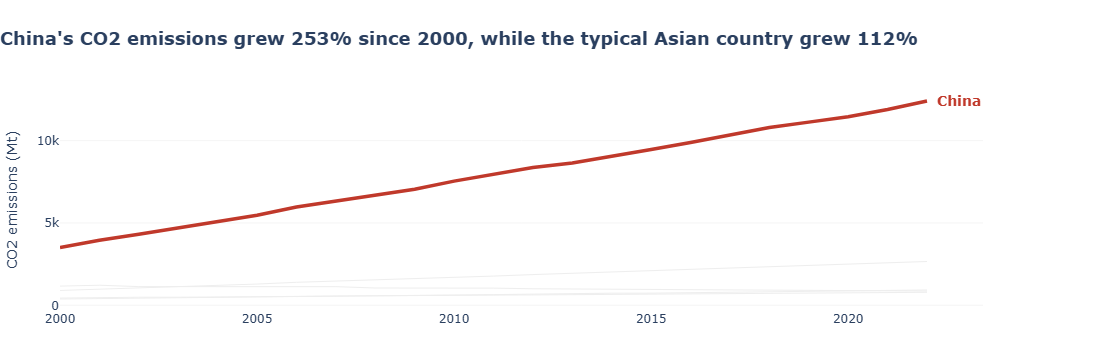

In [7]:
# Task — Multi-series line with highlight
# YOUR CODE HERE
import plotly.graph_objects as go

HIGHLIGHT = 'China'                      # your choice, must match a name in the data
GREY, ACCENT = '#EEEEEE', '#C0392B'

# Asian countries only
asia = df[df['Region'].str.contains('Asia', case=False)].sort_values(['Country', 'Year'])
print("Asian countries:", asia['Country'].unique())

first_year, last_year = asia['Year'].min(), asia['Year'].max()

# numbers for the insight title
first = asia[asia['Year'] == first_year].set_index('Country')['CO2_Mt']
last = asia[asia['Year'] == last_year].set_index('Country')['CO2_Mt']
growth = (last / first - 1) * 100
h_growth = growth[HIGHLIGHT]
median_others = growth.drop(HIGHLIGHT).median()

fig = go.Figure()

# 1. all other countries: light grey, thin
for country, g in asia[asia['Country'] != HIGHLIGHT].groupby('Country'):
    fig.add_trace(go.Scatter(
        x=g['Year'], y=g['CO2_Mt'], mode='lines',
        line=dict(color=GREY, width=1),
        hoverinfo='skip', showlegend=False))

# 2. highlighted country on top, in colour
h = asia[asia['Country'] == HIGHLIGHT]
fig.add_trace(go.Scatter(
    x=h['Year'], y=h['CO2_Mt'], mode='lines',
    line=dict(color=ACCENT, width=3.5), showlegend=False))

# 3. direct label at the end of the line (no legend)
fig.add_annotation(
    x=last_year, y=h['CO2_Mt'].iloc[-1], text=f"<b>{HIGHLIGHT}</b>",
    xanchor='left', xshift=8, showarrow=False,
    font=dict(color=ACCENT, size=14))

# 4. clean layout with insight title
fig.update_layout(
    title=dict(
        text=(f"<b>{HIGHLIGHT}'s CO2 emissions grew {h_growth:.0f}% since {first_year}, "
              f"while the typical Asian country grew {median_others:.0f}%</b>"),
        x=0, font=dict(size=18)),
    plot_bgcolor='white', paper_bgcolor='white',
    margin=dict(l=60, r=110, t=90, b=50),
    xaxis=dict(showgrid=False, showline=False, tickangle=0, title=None),
    yaxis=dict(gridcolor='#F5F5F5', zeroline=False, showline=False,
               title='CO2 emissions (Mt)'),
    showlegend=False)

fig.show()